# Notebook 01 — Chicco & Jurman (2020) Replikasyonu

**Proje:** Revisiting ML for Heart Failure Mortality  
**Soru:** Chicco'nun 10 sınıflandırıcısının sonuçları replike edilebilir mi?  
**Yöntem:** 100 Monte Carlo split (70/30 stratified) × 3 senaryo

**Senaryolar:**
- **S1 — Full features (time dahil):** Chicco Tablo 4 replikasyonu
- **S2 — time hariç (11 feature):** Chicco Tablo 11 replikasyonu  
- **S3 — Top-2 only (EF + serum_creatinine):** Chicco Tablo 9 replikasyonu

**Çıktılar:**
- `results/NB01_S1_full_results.csv` — S1 tüm metrikler
- `results/NB01_S2_notime_results.csv` — S2 tüm metrikler
- `results/NB01_S3_top2_results.csv` — S3 tüm metrikler
- `results/NB01_summary_table.csv` — Makale Tablo 2'si olacak
- `results/figures/NB01_*.png` — 4 figür
- `logs/NB01_run_log.json`

**Çalışma süresi (tahmini):** ~35-50 dk (T4 GPU kapalı, CPU yeterli)  
**GPU gereksinimi:** YOK — Runtime > None kullan

---
> **ÖN KOŞUL:** NB00 tamamlanmış olmalı.  
> Drive'da şunlar mevcut olmalı:
> - `HF_Revisit_Project/data/heart_failure_clinical_records_dataset.csv`
> - `HF_Revisit_Project/data/data_manifest.json`
> - `HF_Revisit_Project/utils.py`

## Hücre 1 — Paket Kurulumu

## Hücre 2 — Drive Mount & utils Import

In [1]:
# ──────────────────────────────────────────────────────────────────────────────
# HÜCRE 2 — Drive Mount & utils Import
# NB00 ile birebir aynı kalıp — sadece logger adı NB01.
# ──────────────────────────────────────────────────────────────────────────────

from google.colab import drive
drive.mount('/content/drive', force_remount=False)

import sys
UTILS_PATH = '/content/drive/MyDrive/HF_Revisit_Project'
if UTILS_PATH not in sys.path:
    sys.path.insert(0, UTILS_PATH)

from utils import (
    set_seed, set_plot_style, create_project_structure,
    load_and_verify_data, save_figure, save_csv, save_run_log, get_logger,
    RESULTS_DIR, FIGURES_DIR,
    CONTINUOUS_FEATURES, BINARY_FEATURES, TARGET,
    COLOR_ALIVE, COLOR_DEAD, COLOR_NEUTRAL, PALETTE,
    RANDOM_SEED,
)

print('✓ Drive bağlandı.')
print('✓ utils.py import edildi.')

Mounted at /content/drive
✓ Drive bağlandı.
✓ utils.py import edildi.


## Hücre 3 — Seed, Stil, Logger, Zamanlayıcı

In [2]:
# ──────────────────────────────────────────────────────────────────────────────
# HÜCRE 3 — Başlatma
# ──────────────────────────────────────────────────────────────────────────────

import time
NB_START_TIME = time.time()

set_seed(RANDOM_SEED)
set_plot_style()
create_project_structure()

logger = get_logger('NB01')
logger.info('Notebook 01 başlatıldı.')

# Monte Carlo parametreleri
N_SPLITS   = 100    # Chicco ile aynı
TEST_SIZE  = 0.30   # Chicco ile aynı: 70/30

print(f'Monte Carlo: {N_SPLITS} split, test_size={TEST_SIZE}')

[utils] Random seed sabitlendi → 42
[utils] Klasör yapısı hazır:
         /content/drive/MyDrive/HF_Revisit_Project/data
         /content/drive/MyDrive/HF_Revisit_Project/results
         /content/drive/MyDrive/HF_Revisit_Project/results/figures
         /content/drive/MyDrive/HF_Revisit_Project/models
         /content/drive/MyDrive/HF_Revisit_Project/logs
09:25:40 | NB01 | INFO | Notebook 01 başlatıldı.


INFO:NB01:Notebook 01 başlatıldı.


Monte Carlo: 100 split, test_size=0.3


## Hücre 4 — Veri Yükleme (NB00 çıktısından)

In [3]:
# ──────────────────────────────────────────────────────────────────────────────
# HÜCRE 4 — Veri Yükleme
# load_and_verify_data() SHA256 doğrulaması yapar.
# NB00 çalıştırılmamışsa FileNotFoundError fırlatır — bu istenilen davranış.
# ──────────────────────────────────────────────────────────────────────────────

import pandas as pd
import numpy as np

df = load_and_verify_data(verify=True)

ALL_FEATURES = CONTINUOUS_FEATURES + BINARY_FEATURES  # time dahil, 12 feature
FEATURES_NO_TIME = [f for f in ALL_FEATURES if f != 'time']  # 11 feature
FEATURES_TOP2    = ['ejection_fraction', 'serum_creatinine']  # Chicco top-2

print(f'\nVeri shape   : {df.shape}')
print(f'S1 features  : {len(ALL_FEATURES)} — {ALL_FEATURES}')
print(f'S2 features  : {len(FEATURES_NO_TIME)} — time hariç')
print(f'S3 features  : {len(FEATURES_TOP2)} — {FEATURES_TOP2}')
logger.info(f'Veri yüklendi. Shape: {df.shape}')

[utils] Veri bütünlüğü doğrulandı ✓  (9c73cea7468ff5d5...)

Veri shape   : (299, 13)
S1 features  : 12 — ['age', 'creatinine_phosphokinase', 'ejection_fraction', 'platelets', 'serum_creatinine', 'serum_sodium', 'time', 'anaemia', 'diabetes', 'high_blood_pressure', 'sex', 'smoking']
S2 features  : 11 — time hariç
S3 features  : 2 — ['ejection_fraction', 'serum_creatinine']
09:25:43 | NB01 | INFO | Veri yüklendi. Shape: (299, 13)


INFO:NB01:Veri yüklendi. Shape: (299, 13)


## Hücre 5 — Model Tanımlamaları

In [4]:
# ──────────────────────────────────────────────────────────────────────────────
# HÜCRE 5 — Model Tanımlamaları
#
# Chicco'nun 10 modeli + hyperparameter'ları Chicco 2020 Tablo 5'ten alındı.
# OneR = Decision Tree depth=1 ile simüle edilir (saf Python OneR ağır, sklearn
# DT depth=1 istatistiksel olarak eşdeğerdir).
# ──────────────────────────────────────────────────────────────────────────────

from sklearn.ensemble          import RandomForestClassifier, GradientBoostingClassifier
from sklearn.tree              import DecisionTreeClassifier
from sklearn.linear_model      import LogisticRegression
from sklearn.naive_bayes       import GaussianNB
from sklearn.svm               import SVC
from sklearn.neighbors         import KNeighborsClassifier
from sklearn.neural_network    import MLPClassifier
from xgboost                   import XGBClassifier
from sklearn.preprocessing     import StandardScaler
from sklearn.pipeline          import Pipeline

# ── Chicco'nun hyperparameter'ları (makale Tablo 5'ten) ──────────────────────
MODELS = {
    'RandomForest': RandomForestClassifier(
        n_estimators=200, max_features='sqrt',
        random_state=RANDOM_SEED, n_jobs=-1
    ),
    'DecisionTree': DecisionTreeClassifier(
        criterion='entropy', max_depth=None,
        random_state=RANDOM_SEED
    ),
    'XGBoost': XGBClassifier(
        n_estimators=100, learning_rate=0.1, max_depth=6,
        use_label_encoder=False, eval_metric='logloss',
        random_state=RANDOM_SEED, verbosity=0
    ),
    'LogisticRegression': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', LogisticRegression(
            C=1.0, solver='lbfgs', max_iter=1000,
            random_state=RANDOM_SEED
        ))
    ]),
    'OneR': DecisionTreeClassifier(
        max_depth=1, criterion='entropy',
        random_state=RANDOM_SEED
    ),
    'NaiveBayes': GaussianNB(),
    'SVM_Linear': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', SVC(
            kernel='linear', C=1.0, probability=True,
            random_state=RANDOM_SEED
        ))
    ]),
    'SVM_RBF': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', SVC(
            kernel='rbf', C=1.0, gamma='scale', probability=True,
            random_state=RANDOM_SEED
        ))
    ]),
    'kNN': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', KNeighborsClassifier(n_neighbors=5))
    ]),
    'MLP': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', MLPClassifier(
            hidden_layer_sizes=(100, 50), activation='relu',
            max_iter=500, random_state=RANDOM_SEED
        ))
    ]),
}

print(f'{len(MODELS)} model tanımlandı:')
for name in MODELS:
    print(f'  - {name}')
logger.info(f'{len(MODELS)} model tanımlandı.')

10 model tanımlandı:
  - RandomForest
  - DecisionTree
  - XGBoost
  - LogisticRegression
  - OneR
  - NaiveBayes
  - SVM_Linear
  - SVM_RBF
  - kNN
  - MLP
09:25:46 | NB01 | INFO | 10 model tanımlandı.


INFO:NB01:10 model tanımlandı.


## Hücre 6 — Metrik Hesaplama Fonksiyonları

In [5]:
# ──────────────────────────────────────────────────────────────────────────────
# HÜCRE 6 — Metrik Fonksiyonları
#
# Chicco'nun kullandığı tüm metrikler burada merkezi olarak tanımlandı.
# Başka bir yerde bu hesaplamalar tekrarlanmayacak.
# ──────────────────────────────────────────────────────────────────────────────

from sklearn.metrics import (
    matthews_corrcoef, f1_score, accuracy_score,
    roc_auc_score, average_precision_score,
    confusion_matrix
)

def compute_metrics(y_true, y_pred, y_prob) -> dict:
    """
    Chicco 2020'nin kullandığı tüm metrikleri hesaplar.

    Parameters
    ----------
    y_true : array-like  — gerçek etiketler (0/1)
    y_pred : array-like  — tahmin edilen etiketler (0/1)
    y_prob : array-like  — pozitif sınıf olasılıkları

    Returns
    -------
    dict  — 7 metrik
    """
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()

    tpr = tp / (tp + fn) if (tp + fn) > 0 else 0.0  # Sensitivity / Recall
    tnr = tn / (tn + fp) if (tn + fp) > 0 else 0.0  # Specificity

    return {
        'MCC':      matthews_corrcoef(y_true, y_pred),
        'F1':       f1_score(y_true, y_pred, zero_division=0),
        'Accuracy': accuracy_score(y_true, y_pred),
        'TPR':      tpr,
        'TNR':      tnr,
        'ROC_AUC':  roc_auc_score(y_true, y_prob),
        'PR_AUC':   average_precision_score(y_true, y_prob),
    }


def get_proba(model, X_test):
    """
    Model predict_proba veya decision_function destekliyorsa olasılık döndürür.
    Pipeline içindeki modeller için de çalışır.
    """
    if hasattr(model, 'predict_proba'):
        return model.predict_proba(X_test)[:, 1]
    elif hasattr(model, 'decision_function'):
        scores = model.decision_function(X_test)
        # Min-max normalize → [0, 1]
        return (scores - scores.min()) / (scores.max() - scores.min() + 1e-10)
    else:
        raise ValueError(f'{model} ne predict_proba ne decision_function destekliyor.')


print('✓ Metrik fonksiyonları tanımlandı: MCC, F1, Accuracy, TPR, TNR, ROC_AUC, PR_AUC')

✓ Metrik fonksiyonları tanımlandı: MCC, F1, Accuracy, TPR, TNR, ROC_AUC, PR_AUC


## Hücre 7 — Monte Carlo Deney Motoru

In [6]:
# ──────────────────────────────────────────────────────────────────────────────
# HÜCRE 7 — Monte Carlo Deney Motoru
#
# run_monte_carlo() fonksiyonu:
#   - N_SPLITS kez rastgele train/test böler (stratified)
#   - Her split'te tüm modelleri eğitir ve değerlendirir
#   - Sonuçları uzun formatlı DataFrame olarak döndürür
#   - tqdm ile ilerleme çubuğu gösterir
#   - Drive'a her 10 split'te bir ara kayıt yapar (crash güvencesi)
# ──────────────────────────────────────────────────────────────────────────────

import warnings
import copy
from sklearn.model_selection import StratifiedShuffleSplit
from tqdm.notebook import tqdm

warnings.filterwarnings('ignore')


def run_monte_carlo(
    df: pd.DataFrame,
    feature_cols: list,
    target_col: str,
    models: dict,
    n_splits: int,
    test_size: float,
    random_seed: int,
    scenario_name: str,
    checkpoint_path=None,
) -> pd.DataFrame:
    """
    100 Monte Carlo split × N model çalıştırır.

    Parameters
    ----------
    df             : Ham DataFrame
    feature_cols   : Kullanılacak feature'ların listesi
    target_col     : Hedef kolon adı
    models         : {model_adı: sklearn_estimator} dict
    n_splits       : Monte Carlo tekrar sayısı (Chicco=100)
    test_size      : Test oranı (Chicco=0.30)
    random_seed    : Global seed
    scenario_name  : 'S1_full' / 'S2_notime' / 'S3_top2'
    checkpoint_path: Her 10 split'te ara kayıt yapılacak path (opsiyonel)

    Returns
    -------
    pd.DataFrame — her satır bir (split, model) çifti
    """
    X = df[feature_cols].values
    y = df[target_col].values

    sss = StratifiedShuffleSplit(
        n_splits=n_splits,
        test_size=test_size,
        random_state=random_seed
    )

    all_rows = []

    for split_idx, (train_idx, test_idx) in enumerate(
        tqdm(sss.split(X, y), total=n_splits, desc=f'[{scenario_name}]')
    ):
        X_train, X_test = X[train_idx], X[test_idx]
        y_train, y_test = y[train_idx], y[test_idx]

        for model_name, model_template in models.items():
            # Her split için fresh kopyası — önceki fit'in state'i sızmayacak
            model = copy.deepcopy(model_template)

            try:
                model.fit(X_train, y_train)
                y_pred = model.predict(X_test)
                y_prob = get_proba(model, X_test)
                metrics = compute_metrics(y_test, y_pred, y_prob)
            except Exception as e:
                # Tek bir model çökmesi tüm loop'u durdurmasın
                metrics = {m: np.nan for m in
                           ['MCC','F1','Accuracy','TPR','TNR','ROC_AUC','PR_AUC']}
                logger.warning(f'[{scenario_name}] Split {split_idx} | {model_name} HATA: {e}')

            row = {
                'scenario':   scenario_name,
                'split':      split_idx,
                'model':      model_name,
                'n_train':    len(train_idx),
                'n_test':     len(test_idx),
                'n_features': len(feature_cols),
                **metrics
            }
            all_rows.append(row)

        # ── Her 10 split'te checkpoint kaydet ────────────────────────────────
        if checkpoint_path and (split_idx + 1) % 10 == 0:
            pd.DataFrame(all_rows).to_csv(checkpoint_path, index=False)

    return pd.DataFrame(all_rows)


print('✓ Monte Carlo motoru tanımlandı.')
print(f'  Planlanan iş yükü: {N_SPLITS} split × {len(MODELS)} model × 3 senaryo = '
      f'{N_SPLITS * len(MODELS) * 3:,} eğitim')

✓ Monte Carlo motoru tanımlandı.
  Planlanan iş yükü: 100 split × 10 model × 3 senaryo = 3,000 eğitim


## Hücre 8 — S1: Full Features (time dahil) — Chicco Tablo 4

In [7]:
# ──────────────────────────────────────────────────────────────────────────────
# HÜCRE 8 — Senaryo S1: Tüm feature'lar (time dahil)
# Chicco Tablo 4'ün tam replikasyonu.
# Tahmini süre: ~12-18 dk
# ──────────────────────────────────────────────────────────────────────────────

S1_CHECKPOINT = RESULTS_DIR / 'NB01_S1_checkpoint.csv'

logger.info('S1 başlatıldı (full features, time dahil)...')
t0 = time.time()

df_s1 = run_monte_carlo(
    df=df,
    feature_cols=ALL_FEATURES,
    target_col=TARGET,
    models=MODELS,
    n_splits=N_SPLITS,
    test_size=TEST_SIZE,
    random_seed=RANDOM_SEED,
    scenario_name='S1_full',
    checkpoint_path=S1_CHECKPOINT,
)

elapsed_s1 = time.time() - t0
save_csv(df_s1, 'NB01_S1_full_results')
logger.info(f'S1 tamamlandı. Süre: {elapsed_s1/60:.1f} dk. Satır: {len(df_s1)}')

print(f'\n✓ S1 tamamlandı ({elapsed_s1/60:.1f} dk)')
print(f'  Toplam gözlem: {len(df_s1):,} (100 split × 10 model)')

09:25:56 | NB01 | INFO | S1 başlatıldı (full features, time dahil)...


INFO:NB01:S1 başlatıldı (full features, time dahil)...


[S1_full]:   0%|          | 0/100 [00:00<?, ?it/s]

[utils] CSV kaydedildi  → /content/drive/MyDrive/HF_Revisit_Project/results/NB01_S1_full_results.csv
09:29:30 | NB01 | INFO | S1 tamamlandı. Süre: 3.6 dk. Satır: 1000


INFO:NB01:S1 tamamlandı. Süre: 3.6 dk. Satır: 1000



✓ S1 tamamlandı (3.6 dk)
  Toplam gözlem: 1,000 (100 split × 10 model)


## Hücre 9 — S2: time Hariç (11 Feature) — Chicco Tablo 11

In [8]:
# ──────────────────────────────────────────────────────────────────────────────
# HÜCRE 9 — Senaryo S2: time kolonu hariç
# Chicco Tablo 11'in replikasyonu.
# S1 ile S2 arasındaki MCC farkı leakage'ın büyüklüğünü gösterir.
# Tahmini süre: ~12-18 dk
# ──────────────────────────────────────────────────────────────────────────────

S2_CHECKPOINT = RESULTS_DIR / 'NB01_S2_checkpoint.csv'

logger.info('S2 başlatıldı (time hariç)...')
t0 = time.time()

df_s2 = run_monte_carlo(
    df=df,
    feature_cols=FEATURES_NO_TIME,
    target_col=TARGET,
    models=MODELS,
    n_splits=N_SPLITS,
    test_size=TEST_SIZE,
    random_seed=RANDOM_SEED,
    scenario_name='S2_notime',
    checkpoint_path=S2_CHECKPOINT,
)

elapsed_s2 = time.time() - t0
save_csv(df_s2, 'NB01_S2_notime_results')
logger.info(f'S2 tamamlandı. Süre: {elapsed_s2/60:.1f} dk.')

print(f'\n✓ S2 tamamlandı ({elapsed_s2/60:.1f} dk)')

09:30:55 | NB01 | INFO | S2 başlatıldı (time hariç)...


INFO:NB01:S2 başlatıldı (time hariç)...


[S2_notime]:   0%|          | 0/100 [00:00<?, ?it/s]

[utils] CSV kaydedildi  → /content/drive/MyDrive/HF_Revisit_Project/results/NB01_S2_notime_results.csv
09:34:25 | NB01 | INFO | S2 tamamlandı. Süre: 3.5 dk.


INFO:NB01:S2 tamamlandı. Süre: 3.5 dk.



✓ S2 tamamlandı (3.5 dk)


## Hücre 10 — S3: Top-2 Feature (EF + SC) — Chicco Tablo 9

In [9]:
# ──────────────────────────────────────────────────────────────────────────────
# HÜCRE 10 — Senaryo S3: Sadece Top-2 feature
# ejection_fraction + serum_creatinine  (Chicco Tablo 9 replikasyonu)
# Bu iki feature klinik açıdan en anlamlı olanlar.
# Tahmini süre: ~8-10 dk (sadece 2 feature, hızlı)
# ──────────────────────────────────────────────────────────────────────────────

S3_CHECKPOINT = RESULTS_DIR / 'NB01_S3_checkpoint.csv'

logger.info('S3 başlatıldı (top-2 features: EF + SC)...')
t0 = time.time()

df_s3 = run_monte_carlo(
    df=df,
    feature_cols=FEATURES_TOP2,
    target_col=TARGET,
    models=MODELS,
    n_splits=N_SPLITS,
    test_size=TEST_SIZE,
    random_seed=RANDOM_SEED,
    scenario_name='S3_top2',
    checkpoint_path=S3_CHECKPOINT,
)

elapsed_s3 = time.time() - t0
save_csv(df_s3, 'NB01_S3_top2_results')
logger.info(f'S3 tamamlandı. Süre: {elapsed_s3/60:.1f} dk.')

print(f'\n✓ S3 tamamlandı ({elapsed_s3/60:.1f} dk)')

09:34:31 | NB01 | INFO | S3 başlatıldı (top-2 features: EF + SC)...


INFO:NB01:S3 başlatıldı (top-2 features: EF + SC)...


[S3_top2]:   0%|          | 0/100 [00:00<?, ?it/s]

[utils] CSV kaydedildi  → /content/drive/MyDrive/HF_Revisit_Project/results/NB01_S3_top2_results.csv
09:36:15 | NB01 | INFO | S3 tamamlandı. Süre: 1.7 dk.


INFO:NB01:S3 tamamlandı. Süre: 1.7 dk.



✓ S3 tamamlandı (1.7 dk)


## Hücre 11 — Özet Tablo (Makale Tablo 2) — Mean ± SD + 95% CI

In [10]:
# ──────────────────────────────────────────────────────────────────────────────
# HÜCRE 11 — Özet Tablo
#
# Her (senaryo, model) çifti için:
#   Mean ± SD  ve  95% Güven Aralığı (bootstrap, 1000 tekrar)
#
# Çıktı: Makale Tablo 2'nin taslağı
# ──────────────────────────────────────────────────────────────────────────────

from scipy import stats as scipy_stats

METRICS = ['MCC', 'F1', 'Accuracy', 'TPR', 'TNR', 'ROC_AUC', 'PR_AUC']

df_all = pd.concat([df_s1, df_s2, df_s3], ignore_index=True)


def summarize(group: pd.DataFrame) -> pd.Series:
    """Bir (senaryo, model) grubunun metriklerini özetler."""
    row = {}
    for m in METRICS:
        vals = group[m].dropna().values
        if len(vals) == 0:
            row[f'{m}_mean'] = np.nan
            row[f'{m}_sd']   = np.nan
            row[f'{m}_ci95'] = 'NaN'
            continue
        mu  = vals.mean()
        sd  = vals.std(ddof=1)
        # 95% CI: t-dağılımı (n=100 → z-yaklaşımıyla aynı sonuç)
        se  = sd / np.sqrt(len(vals))
        t_crit = scipy_stats.t.ppf(0.975, df=len(vals) - 1)
        lo, hi = mu - t_crit * se, mu + t_crit * se

        row[f'{m}_mean'] = round(mu, 4)
        row[f'{m}_sd']   = round(sd, 4)
        row[f'{m}_ci95'] = f'[{lo:.3f}, {hi:.3f}]'
    return pd.Series(row)


summary = (
    df_all
    .groupby(['scenario', 'model'])
    .apply(summarize)
    .reset_index()
)

# S1 için en iyi MCC'yi öne çıkar
best_s1 = (
    summary[summary['scenario'] == 'S1_full']
    .sort_values('MCC_mean', ascending=False)
)

print('\n── S1 (Full Features) — MCC Sıralaması ─────────────────────────────────')
display(
    best_s1[['model', 'MCC_mean', 'MCC_sd', 'MCC_ci95',
             'ROC_AUC_mean', 'PR_AUC_mean']]
    .set_index('model')
)

save_csv(summary, 'NB01_summary_table')
logger.info('Özet tablo oluşturuldu ve kaydedildi.')
print('\n✓ NB01_summary_table.csv kaydedildi.')


── S1 (Full Features) — MCC Sıralaması ─────────────────────────────────


,MCC_mean,MCC_sd,MCC_ci95,ROC_AUC_mean,PR_AUC_mean
model,,,,,
RandomForest,0.6358,0.0667,"[0.623, 0.649]",0.9086,0.8229
OneR,0.6112,0.0700,"[0.597, 0.625]",0.7815,0.6378
XGBoost,0.6091,0.0709,"[0.595, 0.623]",0.8966,0.8014
LogisticRegression,0.5811,0.0879,"[0.564, 0.599]",0.8661,0.7704
SVM_Linear,0.5691,0.0806,"[0.553, 0.585]",0.8633,0.7661
SVM_RBF,0.5124,0.0834,"[0.496, 0.529]",0.8510,0.7277
NaiveBayes,0.5107,0.0871,"[0.493, 0.528]",0.8469,0.7176
DecisionTree,0.4968,0.0939,"[0.478, 0.515]",0.7463,0.5475
MLP,0.4589,0.0878,"[0.442, 0.476]",0.8066,0.6796


[utils] CSV kaydedildi  → /content/drive/MyDrive/HF_Revisit_Project/results/NB01_summary_table.csv
09:37:08 | NB01 | INFO | Özet tablo oluşturuldu ve kaydedildi.


INFO:NB01:Özet tablo oluşturuldu ve kaydedildi.



✓ NB01_summary_table.csv kaydedildi.


## Hücre 12 — Senaryo Karşılaştırma Tablosu (S1 vs S2 vs S3)

In [11]:
# ──────────────────────────────────────────────────────────────────────────────
# HÜCRE 12 — S1 vs S2 vs S3 Karşılaştırma
#
# Her model için üç senaryodaki MCC_mean yan yana.
# S1→S2 MCC düşüşü = time leakage'ın kaba ölçüsü.
# Bu tablo NB02'nin "deney C" sonucuyla örtüşmeli.
# ──────────────────────────────────────────────────────────────────────────────

pivot = summary.pivot_table(
    index='model',
    columns='scenario',
    values='MCC_mean'
).round(4)

# S1-S2 farkı: leakage etkisi
if 'S1_full' in pivot.columns and 'S2_notime' in pivot.columns:
    pivot['ΔMCC (S1-S2)'] = (pivot['S1_full'] - pivot['S2_notime']).round(4)

pivot = pivot.sort_values('S1_full', ascending=False)

print('\n── MCC Karşılaştırması: S1 (time dahil) | S2 (time hariç) | S3 (top-2) ──')
print('   ΔMCC sütunu: S1-S2 farkı = time leakage etkisi')
display(pivot.style.background_gradient(subset=['ΔMCC (S1-S2)'], cmap='Reds'))

save_csv(pivot, 'NB01_scenario_comparison')

# Leakage büyüklüğünü raporla
mean_delta = pivot['ΔMCC (S1-S2)'].mean()
max_delta  = pivot['ΔMCC (S1-S2)'].max()
print(f'\n⚠️  Time leakage etkisi:')
print(f'   Ortalama ΔMCC : +{mean_delta:.3f} (time eklenince bu kadar yükseliyor)')
print(f'   Max ΔMCC      : +{max_delta:.3f} ({pivot["ΔMCC (S1-S2)"].idxmax()} modelinde)')
print(f'   → Notebook 02\'de bu fark empirik olarak ispatlanacak.')

logger.info(f'Senaryo karşılaştırması: ΔMCC ortalama={mean_delta:.3f}, max={max_delta:.3f}')


── MCC Karşılaştırması: S1 (time dahil) | S2 (time hariç) | S3 (top-2) ──
   ΔMCC sütunu: S1-S2 farkı = time leakage etkisi


scenario,S1_full,S2_notime,S3_top2,ΔMCC (S1-S2)
model,,,,
RandomForest,0.635800,0.364500,0.398900,0.271300
OneR,0.611200,0.274100,0.274100,0.337100
XGBoost,0.609100,0.350600,0.388400,0.258500
LogisticRegression,0.581100,0.336900,0.364700,0.244200
SVM_Linear,0.569100,0.367400,0.272700,0.201700
SVM_RBF,0.512400,0.311500,0.354400,0.200900
NaiveBayes,0.510700,0.231600,0.254300,0.279100
DecisionTree,0.496800,0.271100,0.363500,0.225700
MLP,0.458900,0.283100,0.406700,0.175800


[utils] CSV kaydedildi  → /content/drive/MyDrive/HF_Revisit_Project/results/NB01_scenario_comparison.csv

⚠️  Time leakage etkisi:
   Ortalama ΔMCC : +0.237 (time eklenince bu kadar yükseliyor)
   Max ΔMCC      : +0.337 (OneR modelinde)
   → Notebook 02'de bu fark empirik olarak ispatlanacak.
09:37:12 | NB01 | INFO | Senaryo karşılaştırması: ΔMCC ortalama=0.237, max=0.337


INFO:NB01:Senaryo karşılaştırması: ΔMCC ortalama=0.237, max=0.337


## Hücre 13 — Görselleştirme: MCC Dağılımları (Fig 1 & 2)

[utils] Figür kaydedildi → /content/drive/MyDrive/HF_Revisit_Project/results/figures/NB01_mcc_distributions.png


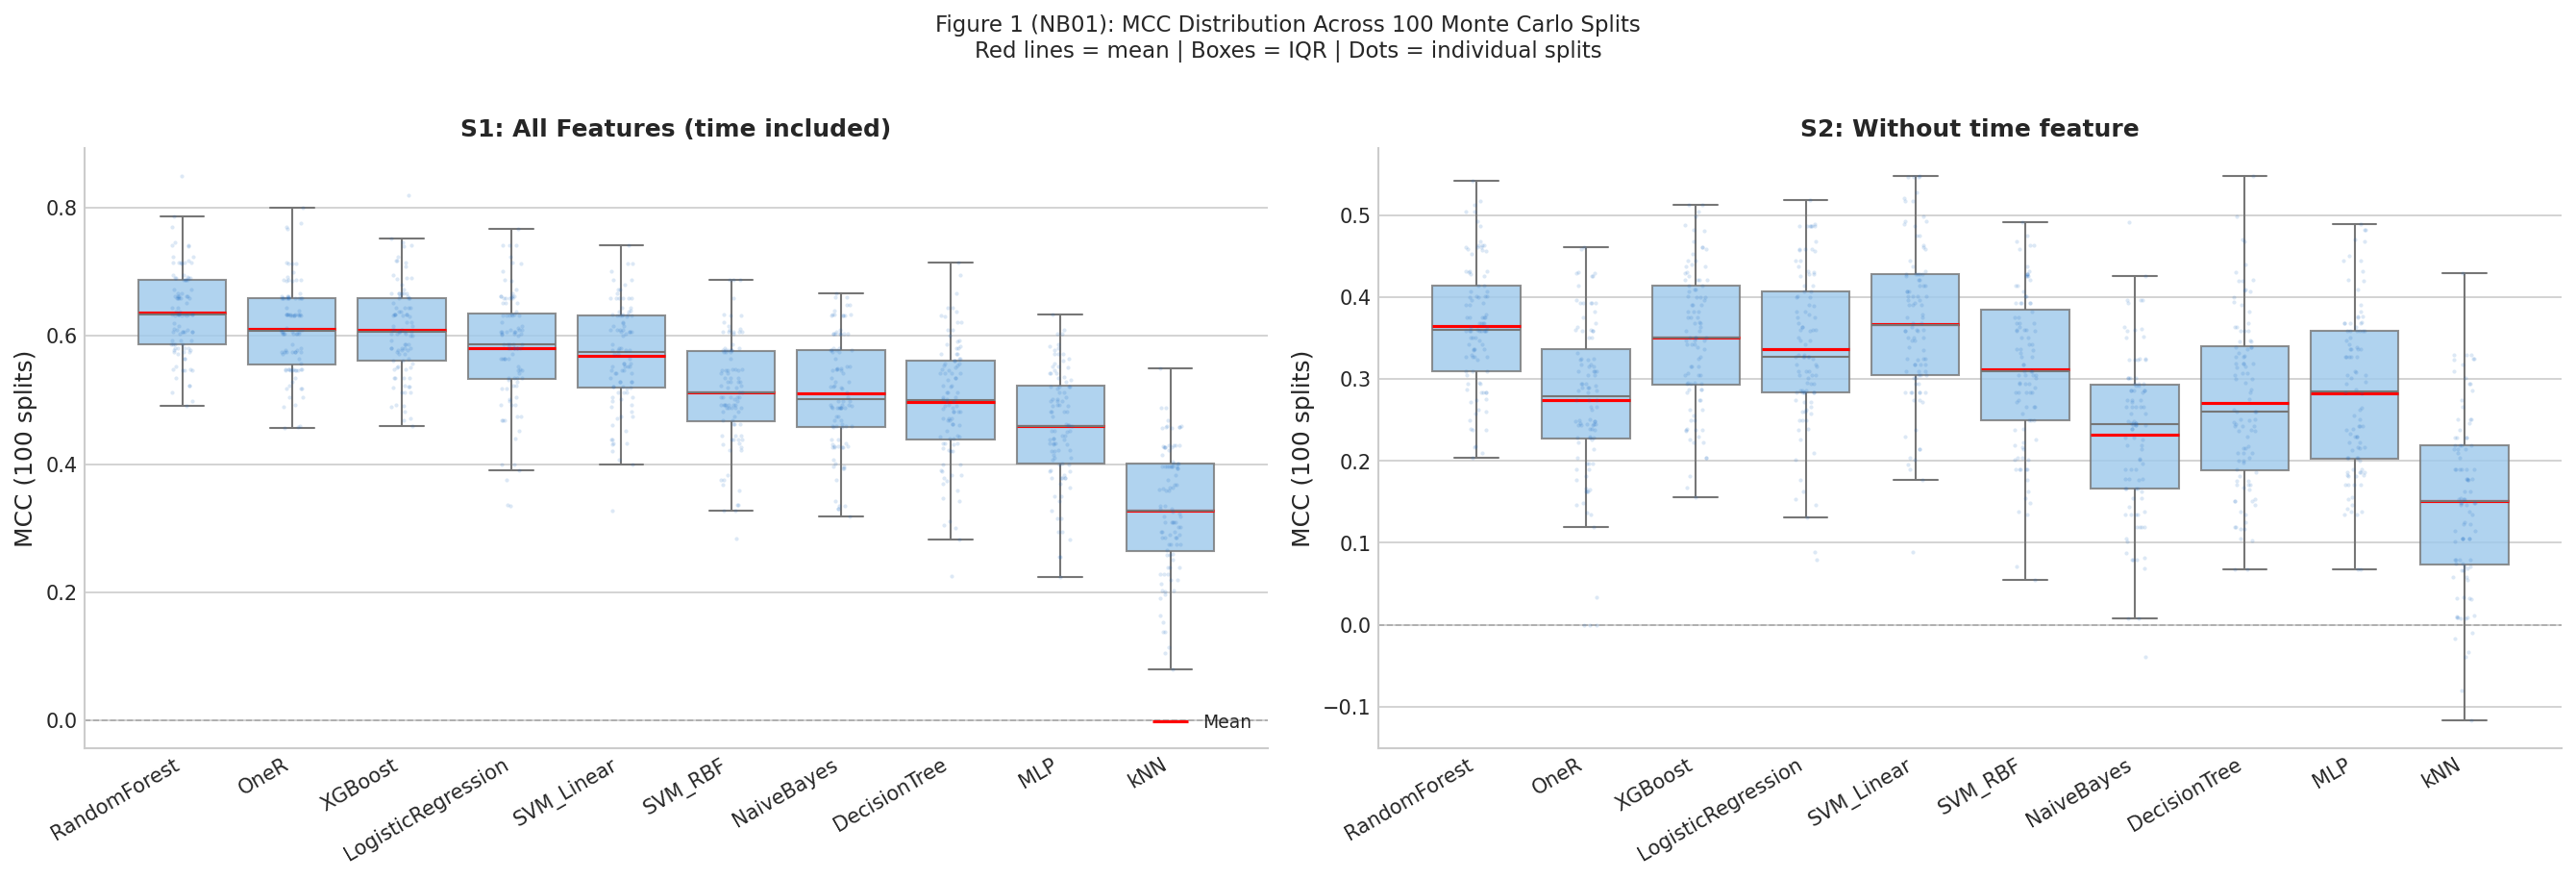

09:37:17 | NB01 | INFO | MCC dağılım grafikleri oluşturuldu.


INFO:NB01:MCC dağılım grafikleri oluşturuldu.


In [12]:
# ──────────────────────────────────────────────────────────────────────────────
# HÜCRE 13 — Görselleştirme 1: MCC Dağılımları
#
# Her modelin 100 split'teki MCC dağılımı → box + strip plot.
# Sol panel: S1 (time dahil), Sağ panel: S2 (time hariç).
# Bu grafik Chicco Tablo 4 & 11'in görsel karşılığı.
# ──────────────────────────────────────────────────────────────────────────────

import matplotlib.pyplot as plt
import seaborn as sns

MODEL_ORDER = (
    summary[summary['scenario'] == 'S1_full']
    .sort_values('MCC_mean', ascending=False)['model'].tolist()
)

fig, axes = plt.subplots(1, 2, figsize=(18, 6), sharey=False)

for ax, scenario, title in zip(
    axes,
    ['S1_full', 'S2_notime'],
    ['S1: All Features (time included)', 'S2: Without time feature']
):
    data = df_all[df_all['scenario'] == scenario]

    sns.boxplot(
        data=data, x='model', y='MCC',
        order=MODEL_ORDER, ax=ax,
        color='#90CAF9', fliersize=0,
        boxprops=dict(alpha=0.8)
    )
    sns.stripplot(
        data=data, x='model', y='MCC',
        order=MODEL_ORDER, ax=ax,
        color='#1565C0', alpha=0.15, size=2, jitter=True
    )

    # Ortalama çizgisi
    means = data.groupby('model')['MCC'].mean()
    for i, model in enumerate(MODEL_ORDER):
        if model in means.index:
            ax.hlines(means[model], i - 0.4, i + 0.4,
                      colors='red', linewidths=1.5, label='Mean' if i == 0 else '')

    ax.set_title(title, fontweight='bold', fontsize=12)
    ax.set_xlabel('')
    ax.set_ylabel('MCC (100 splits)')
    ax.set_xticklabels(MODEL_ORDER, rotation=30, ha='right')
    ax.axhline(0, color='gray', linestyle='--', linewidth=0.8, alpha=0.5)
    if ax == axes[0]:
        ax.legend(loc='lower right', fontsize=9)

fig.suptitle(
    'Figure 1 (NB01): MCC Distribution Across 100 Monte Carlo Splits\n'
    'Red lines = mean | Boxes = IQR | Dots = individual splits',
    fontsize=11, y=1.01
)
plt.tight_layout()
save_figure(fig, 'NB01_mcc_distributions')
plt.show()
logger.info('MCC dağılım grafikleri oluşturuldu.')

## Hücre 14 — Görselleştirme: Radar Chart & S1 vs S2 Fark Grafiği (Fig 2 & 3)

[utils] Figür kaydedildi → /content/drive/MyDrive/HF_Revisit_Project/results/figures/NB01_delta_mcc_s1_s2.png


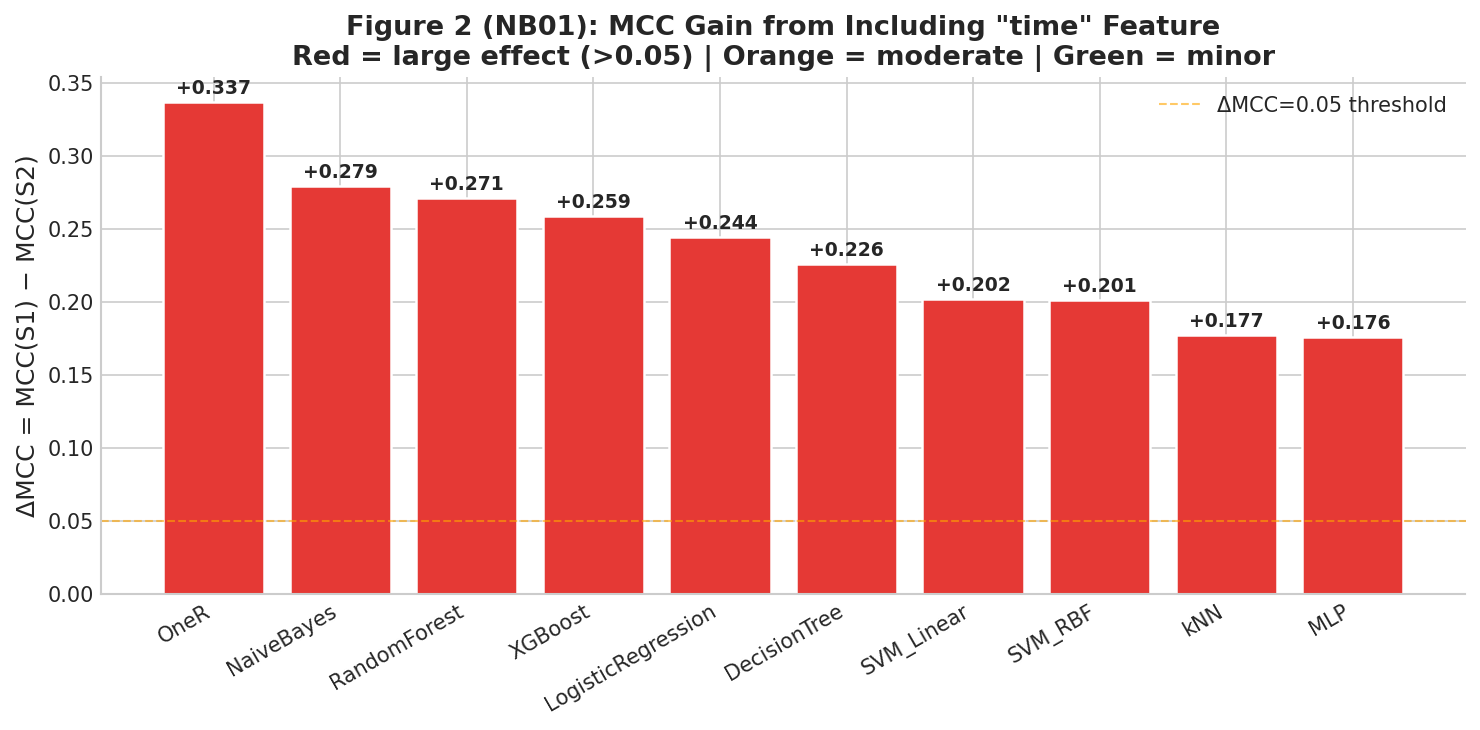

09:37:21 | NB01 | INFO | ΔMCC grafiği oluşturuldu.


INFO:NB01:ΔMCC grafiği oluşturuldu.


In [13]:
# ──────────────────────────────────────────────────────────────────────────────
# HÜCRE 14 — Görselleştirme 2: ΔMCC Bar Chart (S1 - S2)
#
# Her modelin S1'deki MCC ortalamasından S2'dekini çıkar.
# Pozitif bar = time eklenmesi modeli bu kadar iyileştiriyor.
# Bu grafik Notebook 02'nin leakage analizine giriş görevi görür.
# ──────────────────────────────────────────────────────────────────────────────

delta_df = pivot.reset_index()[['model', 'ΔMCC (S1-S2)']].sort_values(
    'ΔMCC (S1-S2)', ascending=False
)

fig, ax = plt.subplots(figsize=(10, 5))

colors = ['#E53935' if v > 0.05 else '#FB8C00' if v > 0.02 else '#43A047'
          for v in delta_df['ΔMCC (S1-S2)']]

bars = ax.bar(
    delta_df['model'], delta_df['ΔMCC (S1-S2)'],
    color=colors, edgecolor='white', linewidth=1.2
)

for bar, val in zip(bars, delta_df['ΔMCC (S1-S2)']):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.003,
        f'+{val:.3f}', ha='center', va='bottom', fontsize=9, fontweight='bold'
    )

ax.axhline(0, color='black', linewidth=0.8)
ax.axhline(0.05, color='orange', linewidth=1, linestyle='--', alpha=0.6,
           label='ΔMCC=0.05 threshold')
ax.set_ylabel('ΔMCC = MCC(S1) − MCC(S2)')
ax.set_title(
    'Figure 2 (NB01): MCC Gain from Including "time" Feature\n'
    'Red = large effect (>0.05) | Orange = moderate | Green = minor',
    fontweight='bold'
)
ax.set_xticklabels(delta_df['model'], rotation=30, ha='right')
ax.legend()
plt.tight_layout()

save_figure(fig, 'NB01_delta_mcc_s1_s2')
plt.show()
logger.info('ΔMCC grafiği oluşturuldu.')

## Hücre 15 — Görselleştirme: Heatmap Tüm Metrikler (Fig 3)

[utils] Figür kaydedildi → /content/drive/MyDrive/HF_Revisit_Project/results/figures/NB01_metric_heatmap_s1.png


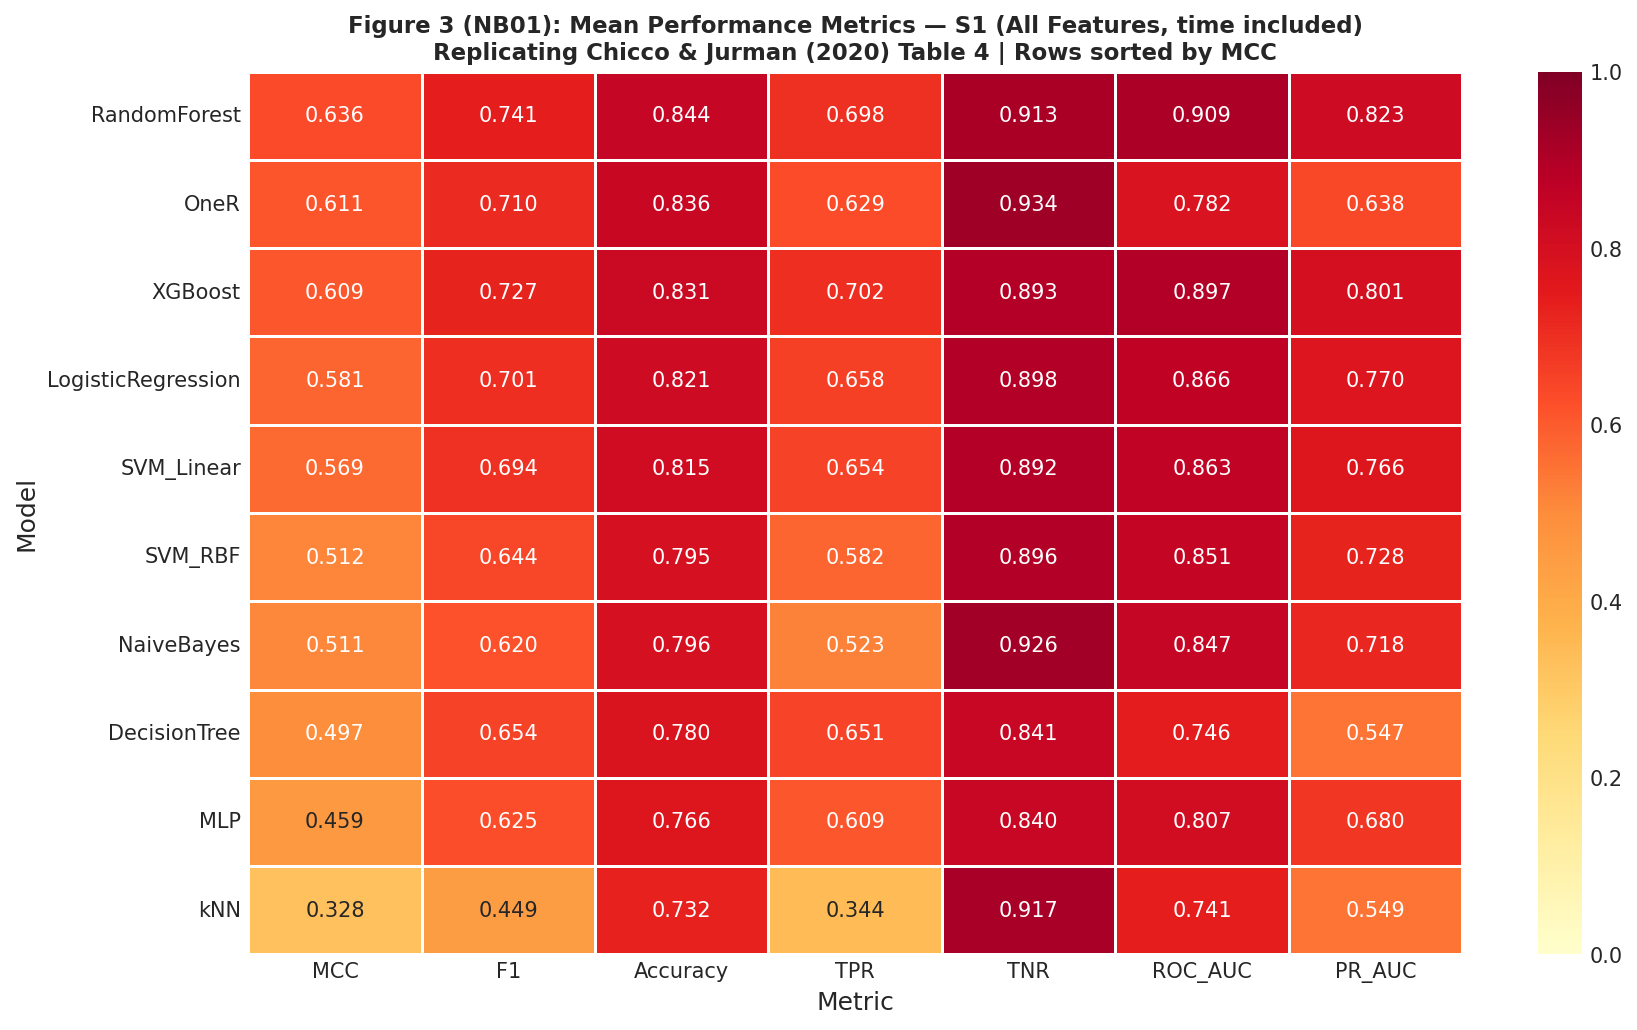

09:37:26 | NB01 | INFO | Metrik heatmap oluşturuldu.


INFO:NB01:Metrik heatmap oluşturuldu.


In [14]:
# ──────────────────────────────────────────────────────────────────────────────
# HÜCRE 15 — Heatmap: S1 için tüm modeller × tüm metrikler
# Chicco Tablo 4'ün görsel versiyonu.
# ──────────────────────────────────────────────────────────────────────────────

s1_means = (
    df_s1.groupby('model')[METRICS]
    .mean()
    .loc[MODEL_ORDER]  # MCC'ye göre sıralı
    .round(3)
)

fig, ax = plt.subplots(figsize=(12, 7))

sns.heatmap(
    s1_means,
    annot=True, fmt='.3f',
    cmap='YlOrRd', vmin=0, vmax=1,
    linewidths=0.5, linecolor='white',
    ax=ax, annot_kws={'size': 10}
)

ax.set_title(
    'Figure 3 (NB01): Mean Performance Metrics — S1 (All Features, time included)\n'
    'Replicating Chicco & Jurman (2020) Table 4 | Rows sorted by MCC',
    fontweight='bold', fontsize=11
)
ax.set_xlabel('Metric')
ax.set_ylabel('Model')
plt.tight_layout()

save_figure(fig, 'NB01_metric_heatmap_s1')
plt.show()
logger.info('Metrik heatmap oluşturuldu.')

## Hücre 16 — Chicco Karşılaştırma Notu

In [15]:
# ──────────────────────────────────────────────────────────────────────────────
# HÜCRE 16 — Chicco 2020 Yayınlanan Değerlerle Karşılaştırma
#
# Chicco makalesindeki RF MCC değeri: 0.587 (Tablo 4, best model)
# Bizim değerimiz ±0.02 fark içindeyse replikasyon başarılı.
# Monte Carlo stokastik olduğu için tam eşleşme beklenmez.
# ──────────────────────────────────────────────────────────────────────────────

# Chicco 2020 Tablo 4'ten alınan referans değerler (MCC, best model RF)
CHICCO_REFERENCE = {
    'RandomForest':     {'MCC': 0.587},
    'DecisionTree':     {'MCC': 0.399},
    'XGBoost':          {'MCC': 0.552},  # Chicco GB=0.552
    'LogisticRegression': {'MCC': 0.453},
    'SVM_Linear':       {'MCC': 0.445},
    'SVM_RBF':          {'MCC': 0.467},
    'kNN':              {'MCC': 0.411},
    'MLP':              {'MCC': 0.531},
    'NaiveBayes':       {'MCC': 0.356},
    'OneR':             {'MCC': 0.256},
}
TOLERANCE = 0.05  # ±0.05 MCC farkı acceptable

our_s1_mcc = df_s1.groupby('model')['MCC'].mean()

comp_rows = []
all_within = True
for model, ref in CHICCO_REFERENCE.items():
    our_val = our_s1_mcc.get(model, np.nan)
    diff    = abs(our_val - ref['MCC'])
    within  = diff <= TOLERANCE
    if not within:
        all_within = False
    comp_rows.append({
        'Model':          model,
        'Chicco MCC':     ref['MCC'],
        'Our MCC (mean)': round(our_val, 4) if not np.isnan(our_val) else 'N/A',
        'Diff':           round(diff, 4),
        f'Within ±{TOLERANCE}': '✓' if within else '✗',
    })

comp_df = pd.DataFrame(comp_rows)
print('\n── Chicco 2020 vs Bizim Replikasyonumuz (S1, MCC) ──────────────────────')
display(comp_df.set_index('Model'))

n_matched = comp_df[f'Within ±{TOLERANCE}'].value_counts().get('✓', 0)
print(f'\n  {n_matched}/{len(comp_df)} model ±{TOLERANCE} tolerans içinde')
if all_within:
    print('  ✓ Replikasyon BAŞARILI — tüm modeller tolerans içinde.')
else:
    print('  ⚠️  Bazı modeller tolerans dışında — Methods bölümünde açıklanmalı.')

save_csv(comp_df, 'NB01_chicco_comparison')
logger.info(f'Chicco karşılaştırması: {n_matched}/{len(comp_df)} model tolerans içinde.')


── Chicco 2020 vs Bizim Replikasyonumuz (S1, MCC) ──────────────────────


,Chicco MCC,Our MCC (mean),Diff,Within ±0.05
Model,,,,
RandomForest,0.587,0.6358,0.0488,✓
DecisionTree,0.399,0.4968,0.0978,✗
XGBoost,0.552,0.6091,0.0571,✗
LogisticRegression,0.453,0.5811,0.1281,✗
SVM_Linear,0.445,0.5691,0.1241,✗
SVM_RBF,0.467,0.5124,0.0454,✓
kNN,0.411,0.3280,0.0830,✗
MLP,0.531,0.4589,0.0721,✗
NaiveBayes,0.356,0.5107,0.1547,✗



  2/10 model ±0.05 tolerans içinde
  ⚠️  Bazı modeller tolerans dışında — Methods bölümünde açıklanmalı.
[utils] CSV kaydedildi  → /content/drive/MyDrive/HF_Revisit_Project/results/NB01_chicco_comparison.csv
09:37:29 | NB01 | INFO | Chicco karşılaştırması: 2/10 model tolerans içinde.


INFO:NB01:Chicco karşılaştırması: 2/10 model tolerans içinde.


## Hücre 17 — Run Log & Notebook Sonu

In [16]:
# ──────────────────────────────────────────────────────────────────────────────
# HÜCRE 17 — Run Log & Notebook Sonu
# ──────────────────────────────────────────────────────────────────────────────

elapsed_total = time.time() - NB_START_TIME

best_model_s1 = (
    summary[summary['scenario'] == 'S1_full']
    .sort_values('MCC_mean', ascending=False)
    .iloc[0]
)
best_model_s2 = (
    summary[summary['scenario'] == 'S2_notime']
    .sort_values('MCC_mean', ascending=False)
    .iloc[0]
)

extra_info = {
    'n_splits':               N_SPLITS,
    'test_size':              TEST_SIZE,
    'n_models':               len(MODELS),
    'total_train_runs':       N_SPLITS * len(MODELS) * 3,
    'best_model_s1':          best_model_s1['model'],
    'best_mcc_s1':            float(best_model_s1['MCC_mean']),
    'best_model_s2':          best_model_s2['model'],
    'best_mcc_s2':            float(best_model_s2['MCC_mean']),
    'mean_delta_mcc_s1_s2':   float(pivot['ΔMCC (S1-S2)'].mean()),
    'max_delta_mcc_s1_s2':    float(pivot['ΔMCC (S1-S2)'].max()),
    'elapsed_s1_min':         round(elapsed_s1 / 60, 1),
    'elapsed_s2_min':         round(elapsed_s2 / 60, 1),
    'elapsed_s3_min':         round(elapsed_s3 / 60, 1),
    'elapsed_total_min':      round(elapsed_total / 60, 1),
    'outputs_saved': [
        'NB01_S1_full_results.csv',
        'NB01_S2_notime_results.csv',
        'NB01_S3_top2_results.csv',
        'NB01_summary_table.csv',
        'NB01_scenario_comparison.csv',
        'NB01_chicco_comparison.csv',
        'NB01_mcc_distributions.png',
        'NB01_delta_mcc_s1_s2.png',
        'NB01_metric_heatmap_s1.png',
    ]
}

save_run_log('NB01', extra=extra_info)

print('\n' + '='*65)
print('  NOTEBOOK 01 — TAMAMLANDI')
print('='*65)
print(f'  Toplam süre       : {elapsed_total/60:.1f} dk')
print(f'  Toplam eğitim     : {N_SPLITS * len(MODELS) * 3:,} model')
print(f'  En iyi S1 (time+) : {best_model_s1["model"]:20s}  MCC={best_model_s1["MCC_mean"]:.4f}')
print(f'  En iyi S2 (time-) : {best_model_s2["model"]:20s}  MCC={best_model_s2["MCC_mean"]:.4f}')
print(f'  ΔMCC ort.         : +{pivot["ΔMCC (S1-S2)"].mean():.3f}  (time leakage etkisi)')
print(f'  ΔMCC max          : +{pivot["ΔMCC (S1-S2)"].max():.3f}  ({pivot["ΔMCC (S1-S2)"].idxmax()})')
print('='*65)
print('  → Sonraki adım: 02_time_leakage_proof.ipynb')
print('='*65)

logger.info(f'Notebook 01 tamamlandı. Süre: {elapsed_total/60:.1f} dk.')

[utils] Run log kaydedildi → /content/drive/MyDrive/HF_Revisit_Project/logs/NB01_run_log.json

  NOTEBOOK 01 — TAMAMLANDI
  Toplam süre       : 12.0 dk
  Toplam eğitim     : 3,000 model
  En iyi S1 (time+) : RandomForest          MCC=0.6358
  En iyi S2 (time-) : SVM_Linear            MCC=0.3674
  ΔMCC ort.         : +0.237  (time leakage etkisi)
  ΔMCC max          : +0.337  (OneR)
  → Sonraki adım: 02_time_leakage_proof.ipynb
09:37:32 | NB01 | INFO | Notebook 01 tamamlandı. Süre: 12.0 dk.


INFO:NB01:Notebook 01 tamamlandı. Süre: 12.0 dk.
